In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re
import nltk
import os
import pickle

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from wordcloud import WordCloud

In [38]:
pip install nltk scikit-learn wordcloud

Note: you may need to restart the kernel to use updated packages.


In [39]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [40]:
file_path = r"C:\Users\Dell\Desktop\Analytics Platform\ecommerce_features.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (2000, 21)


,Order ID,Customer ID,Product ID,Product Name,Product Category,Quantity,Price (INR),Discount (%),Order Date,Customer Location,...,Review,Sales/Revenue (INR),Year,Month,Month Name,Quarter,Day of Week,Discount Amount (INR),Gross Sales (INR),Calculated Revenue (INR)
0,ORD00091,CUST1105,P009,Sneakers,Clothing,5,2907.60,25,2023-09-23,Hyderabad,...,Very disappointing purchase,10903.50,2023,9,September,3,Saturday,3634.5000,14538.00,10903.5000
1,ORD00210,CUST1064,P005,Laptop,Electronics,3,52234.91,15,2024-12-26,Chandigarh,...,Not very satisfied with the product,133199.02,2024,12,December,4,Thursday,23505.7095,156704.73,133199.0205
2,ORD00105,CUST1006,P010,Kurta,Clothing,4,1000.22,20,2026-02-23,Gurugram,...,"Below average, needs improvement",3200.70,2026,2,February,1,Monday,800.1760,4000.88,3200.7040
3,ORD00244,CUST1087,P008,Jacket,Clothing,5,2515.47,5,2023-12-16,Gurugram,...,Not very satisfied with the product,11948.48,2023,12,December,4,Saturday,628.8675,12577.35,11948.4825
4,ORD00014,CUST1119,P015,Table Lamp,Home & Kitchen,3,983.81,0,2021-03-30,Mumbai,...,"Amazing product, highly recommended",2951.43,2021,3,March,1,Tuesday,0.0000,2951.43,2951.4300


In [41]:
# Check the Review column

print("Review column data type:")
print(df["Review"].dtype)

print("\nMissing reviews:")
print(df["Review"].isnull().sum())

print("\nNumber of unique reviews:")
print(df["Review"].nunique())

print("\nSample reviews:")
print(df["Review"].head(10))

Review column data type:
object

Missing reviews:
0

Number of unique reviews:
25

Sample reviews:
0            Very disappointing purchase
1    Not very satisfied with the product
2       Below average, needs improvement
3    Not very satisfied with the product
4    Amazing product, highly recommended
5       Not recommended, poor experience
6               Product quality was poor
7              Excellent value for money
8    Amazing product, highly recommended
9          Average product, satisfactory
Name: Review, dtype: object


In [42]:
#Remove missing reviews

df = df.dropna(subset=["Review"]).copy()

df["Review"] = df["Review"].astype(str)

print("Dataset shape after removing missing reviews:")
print(df.shape)

Dataset shape after removing missing reviews:
(2000, 21)


In [43]:
# Create sentiment labels

def rating_to_sentiment(rating):

    if rating <= 2:
        return "Negative"

    elif rating == 3:
        return "Neutral"

    else:
        return "Positive"


df["Sentiment"] = df["Rating"].apply(rating_to_sentiment)

print(df[["Rating", "Review", "Sentiment"]].head(10))

   Rating                               Review Sentiment
0       1          Very disappointing purchase  Negative
1       2  Not very satisfied with the product  Negative
2       2     Below average, needs improvement  Negative
3       2  Not very satisfied with the product  Negative
4       5  Amazing product, highly recommended  Positive
5       1     Not recommended, poor experience  Negative
6       1             Product quality was poor  Negative
7       5            Excellent value for money  Positive
8       5  Amazing product, highly recommended  Positive
9       3        Average product, satisfactory   Neutral


In [44]:
# Check sentiment distribution

sentiment_counts = df["Sentiment"].value_counts()

print(sentiment_counts)

Sentiment
Positive    1004
Neutral      510
Negative     486
Name: count, dtype: int64


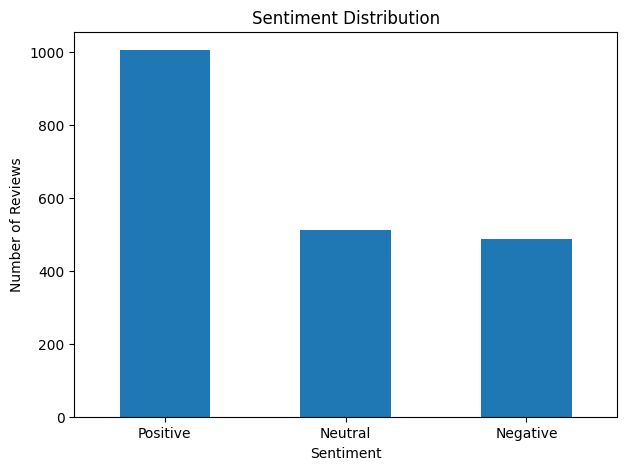

In [45]:
plt.figure(figsize=(7, 5))

sentiment_counts.plot(kind="bar")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.show()

In [46]:
# Clean the review text

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


def clean_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Keep only letters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenize
    words = text.split()

    # Remove stopwords and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

In [47]:
# Apply text cleaning

df["Cleaned_Review"] = df["Review"].apply(clean_text)

df[["Review", "Cleaned_Review"]].head(10)

,Review,Cleaned_Review
0,Very disappointing purchase,disappointing purchase
1,Not very satisfied with the product,satisfied product
2,"Below average, needs improvement",average need improvement
3,Not very satisfied with the product,satisfied product
4,"Amazing product, highly recommended",amazing product highly recommended
5,"Not recommended, poor experience",recommended poor experience
6,Product quality was poor,product quality poor
7,Excellent value for money,excellent value money
8,"Amazing product, highly recommended",amazing product highly recommended
9,"Average product, satisfactory",average product satisfactory


In [51]:
# Remove empty reviews

df = df[df["Cleaned_Review"].str.strip() != ""]

df = df.reset_index(drop=True)

print("Dataset after text cleaning:", df.shape)

Dataset after text cleaning: (2000, 23)


In [52]:
# Split the traning and texting data

X = df["Cleaned_Review"]
y = df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 1600
Testing reviews: 400


In [53]:
# Convert text to TF-IDF

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (1600, 77)
Testing TF-IDF shape: (400, 77)


In [54]:
# Train the sentiment classification model

sentiment_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

sentiment_model.fit(
    X_train_tfidf,
    y_train
)

print("Sentiment classification model trained successfully!")

Sentiment classification model trained successfully!


In [55]:
# Make predictions

y_pred = sentiment_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

print("\nFirst 20 predictions:")
print(y_pred[:20])

Predictions generated successfully!

First 20 predictions:
['Positive' 'Negative' 'Negative' 'Positive' 'Negative' 'Positive'
 'Positive' 'Positive' 'Neutral' 'Negative' 'Positive' 'Neutral' 'Neutral'
 'Positive' 'Neutral' 'Neutral' 'Positive' 'Negative' 'Positive' 'Neutral']


In [56]:
# Evaluate the model

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.965

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      0.86      0.92        97
     Neutral       1.00      1.00      1.00       102
    Positive       0.93      1.00      0.97       201

    accuracy                           0.96       400
   macro avg       0.98      0.95      0.96       400
weighted avg       0.97      0.96      0.96       400



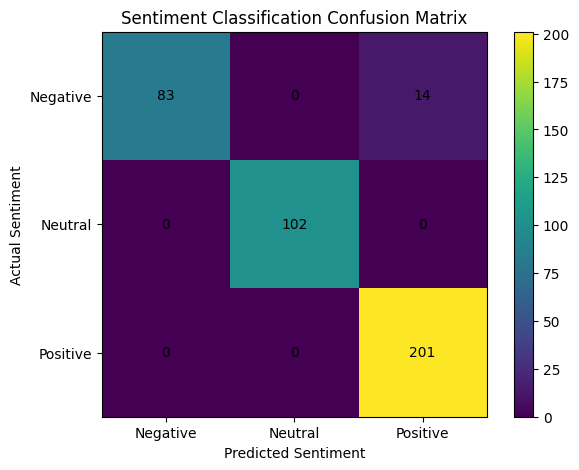

In [57]:
# Confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
)

plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title("Sentiment Classification Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.xticks(
    range(3),
    ["Negative", "Neutral", "Positive"]
)

plt.yticks(
    range(3),
    ["Negative", "Neutral", "Positive"]
)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()

plt.show()

In [58]:
# Predict sentiment for all reviews

all_reviews_tfidf = tfidf.transform(
    df["Cleaned_Review"]
)

df["Predicted_Sentiment"] = sentiment_model.predict(
    all_reviews_tfidf
)

df[[
    "Product Name",
    "Product Category",
    "Rating",
    "Review",
    "Predicted_Sentiment"
]].head(10)

,Product Name,Product Category,Rating,Review,Predicted_Sentiment
0,Sneakers,Clothing,1,Very disappointing purchase,Negative
1,Laptop,Electronics,2,Not very satisfied with the product,Positive
2,Kurta,Clothing,2,"Below average, needs improvement",Negative
3,Jacket,Clothing,2,Not very satisfied with the product,Positive
4,Table Lamp,Home & Kitchen,5,"Amazing product, highly recommended",Positive
5,Bluetooth Speaker,Electronics,1,"Not recommended, poor experience",Negative
6,Perfume,Beauty,1,Product quality was poor,Negative
7,Face Wash,Beauty,5,Excellent value for money,Positive
8,Yoga Mat,Sports,5,"Amazing product, highly recommended",Positive
9,Python Programming,Books,3,"Average product, satisfactory",Neutral


In [59]:
# Sentiment by product

product_sentiment = pd.crosstab(
    df["Product Name"],
    df["Predicted_Sentiment"]
)

product_sentiment.head(10)

Predicted_Sentiment,Negative,Neutral,Positive
Product Name,,,
Badminton Racket,11,11,18
Bedsheet,13,21,29
Bluetooth Speaker,12,9,30
Computer Networks,19,20,59
Cookware Set,13,8,27
Cricket Bat,32,23,55
DBMS,7,13,19
Data Science,17,17,25
Face Wash,23,26,60


In [60]:
product_sentiment_percentage = pd.crosstab(
    df["Product Name"],
    df["Predicted_Sentiment"],
    normalize="index"
) * 100

product_sentiment_percentage = product_sentiment_percentage.round(2)

product_sentiment_percentage.head(10)

Predicted_Sentiment,Negative,Neutral,Positive
Product Name,,,
Badminton Racket,27.50,27.50,45.00
Bedsheet,20.63,33.33,46.03
Bluetooth Speaker,23.53,17.65,58.82
Computer Networks,19.39,20.41,60.20
Cookware Set,27.08,16.67,56.25
Cricket Bat,29.09,20.91,50.00
DBMS,17.95,33.33,48.72
Data Science,28.81,28.81,42.37
Face Wash,21.10,23.85,55.05


In [61]:
# Sentiment by category

category_sentiment = pd.crosstab(
    df["Product Category"],
    df["Predicted_Sentiment"]
)

category_sentiment

Predicted_Sentiment,Negative,Neutral,Positive
Product Category,,,
Beauty,70,97,190
Books,71,90,186
Clothing,60,74,149
Electronics,80,86,191
Home & Kitchen,65,73,161
Sports,83,90,184


In [62]:
category_sentiment_percentage = pd.crosstab(
    df["Product Category"],
    df["Predicted_Sentiment"],
    normalize="index"
) * 100

category_sentiment_percentage.round(2)

Predicted_Sentiment,Negative,Neutral,Positive
Product Category,,,
Beauty,19.61,27.17,53.22
Books,20.46,25.94,53.60
Clothing,21.20,26.15,52.65
Electronics,22.41,24.09,53.50
Home & Kitchen,21.74,24.41,53.85
Sports,23.25,25.21,51.54


In [63]:
# Sentiment vs Rating

sentiment_rating = pd.crosstab(
    df["Rating"],
    df["Predicted_Sentiment"]
)

sentiment_rating

Predicted_Sentiment,Negative,Neutral,Positive
Rating,,,
1,200,0,0
2,229,0,57
3,0,510,0
4,0,0,611
5,0,0,393


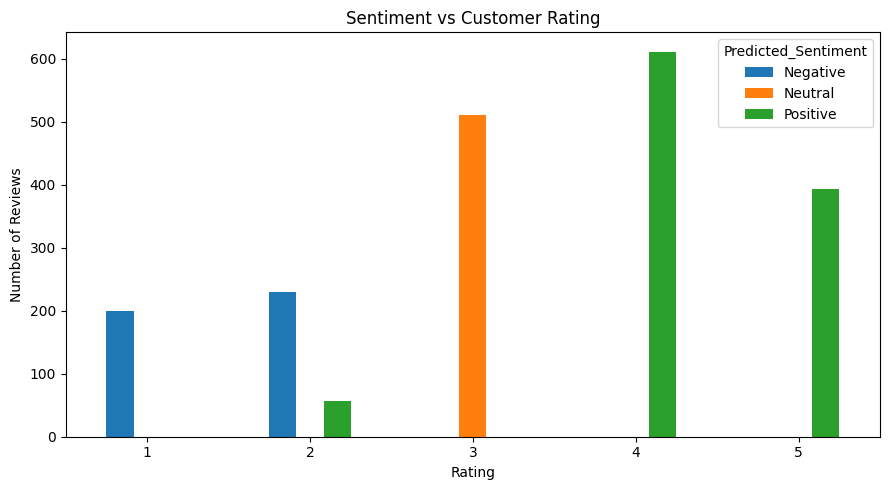

In [64]:
sentiment_rating.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Sentiment vs Customer Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [65]:
# Find products with negative sentiment

negative_products = (
    df[df["Predicted_Sentiment"] == "Negative"]
    .groupby("Product Name")
    .size()
    .sort_values(ascending=False)
)

print("Products with the most negative reviews:")
print(negative_products.head(10))

Products with the most negative reviews:
Product Name
Cricket Bat            32
Face Wash              23
Wireless Headphones    22
Mixer Grinder          19
Machine Learning       19
Computer Networks      19
Jeans                  19
Smartwatch             17
Data Science           17
Moisturizer            17
dtype: int64


In [66]:
# Find Products With Positive Sentiment

positive_products = (
    df[df["Predicted_Sentiment"] == "Positive"]
    .groupby("Product Name")
    .size()
    .sort_values(ascending=False)
)

print("Products with the most positive reviews:")
print(positive_products.head(10))

Products with the most positive reviews:
Product Name
Face Wash            60
Computer Networks    59
Running Shoes        58
Cricket Bat          55
Machine Learning     53
Mixer Grinder        46
Sunscreen            46
Smartwatch           46
Table Lamp           42
Smartphone           42
dtype: int64


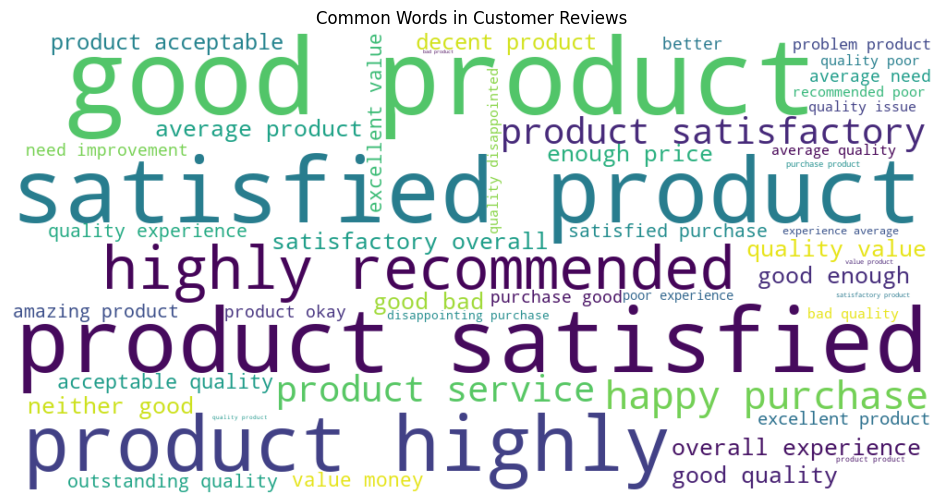

In [67]:
# Create a word cloud

all_text = " ".join(df["Cleaned_Review"])

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(all_text)

plt.figure(figsize=(12, 6))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Common Words in Customer Reviews")

plt.show()

In [68]:
# Save the sentiment dataset

os.makedirs(r"C:\Users\Dell\Desktop\Analytics Platform", exist_ok=True)

output_file = r"C:\Users\Dell\Desktop\Analytics Platform\review_sentiment.csv"

df.to_csv(
    output_file,
    index=False
)

print("Sentiment dataset saved successfully!")
print(output_file)

Sentiment dataset saved successfully!
C:\Users\Dell\Desktop\Analytics Platform\review_sentiment.csv


In [69]:
# Save the ML model

os.makedirs(r"C:\Users\Dell\Desktop\Analytics Platform", exist_ok=True)

sentiment_model_data = {
    "model": sentiment_model,
    "tfidf": tfidf
}

model_file = r"C:\Users\Dell\Desktop\Analytics Platform\sentiment_model.pkl"

with open(model_file, "wb") as file:
    pickle.dump(sentiment_model_data, file)

print("Sentiment model saved successfully!")
print(model_file)

Sentiment model saved successfully!
C:\Users\Dell\Desktop\Analytics Platform\sentiment_model.pkl


In [70]:
# Save analysis result

os.makedirs(r"C:\Users\Dell\Desktop\Analytics Platform", exist_ok=True)

product_sentiment_percentage.to_csv(
    r"C:\Users\Dell\Desktop\Analytics Platform\product_sentiment.csv"
)

category_sentiment_percentage.to_csv(
    r"C:\Users\Dell\Desktop\Analytics Platform\category_sentiment.csv"
)

sentiment_rating.to_csv(
    r"C:\Users\Dell\Desktop\Analytics Platform\sentiment_vs_rating.csv"
)

print("Sentiment analysis results saved successfully!")

Sentiment analysis results saved successfully!


In [71]:
# Verify everthing

print(
    "Sentiment dataset:",
    os.path.exists(r"C:\Users\Dell\Desktop\Analytics Platform\review_sentiment.csv")
)

print(
    "Sentiment model:",
    os.path.exists(r"C:\Users\Dell\Desktop\Analytics Platform\sentiment_model.pkl")
)

print(
    "Product sentiment:",
    os.path.exists(r"C:\Users\Dell\Desktop\Analytics Platform\product_sentiment.csv")
)

print(
    "Category sentiment:",
    os.path.exists(r"C:\Users\Dell\Desktop\Analytics Platform\category_sentiment.csv")
)

print(
    "Sentiment vs rating:",
    os.path.exists(r"C:\Users\Dell\Desktop\Analytics Platform\sentiment_vs_rating.csv")
)

Sentiment dataset: True
Sentiment model: True
Product sentiment: True
Category sentiment: True
Sentiment vs rating: True
